# BC 소비데이터, 새로운 질문으로 다시 보기

**기존 `EDA_full(1).ipynb`를 바탕으로 만든 독립 실행 노트북입니다.**
단순 순위를 반복하기보다, 집단 구성·분모·기간·비교 대상을 바꾸었을 때도 발견이 유지되는지 확인합니다.
미리 정한 공모전 주제를 지지하도록 결과를 만들지 않습니다.

| 새 질문 | 기존 EDA에서 더 나아가는 부분 |
|---|---|
| 금액이 큰 업종과 결제가 많은 업종은 같은가? | 금액·건수의 **비중 차이**를 함께 비교 |
| 외국인의 슈퍼마켓 비중은 지역 차이를 고려해도 높은가? | 같은 지역·월, 이어서 같은 연령에서 비교하고 공통 가중치 적용 |
| 60대 이상은 다른 성인 연령층보다 편의점 비중이 높은가? | 자신을 포함한 전체 평균 대신 **20~50대 내국인**과 비교 |
| 고령층이 많아서 슈퍼마켓 비중이 높은 지역인가? | 월·성별·연령 구성으로 기대되는 건수와 실제 건수를 비교 |
| 금액 증가가 결제건수 증가와 함께 나타났는가? | 같은 집계조합만 남기고 금액 변화를 건수·건당 금액으로 분해 |
| 어디를 후속 조사 후보로 볼 것인가? | 외국인 비중·절대 규모·월별 관측 여부를 함께 제시 |
| 분석 설정을 바꾸면 결론도 뒤집히는가? | 관측량 기준 및 결측조합 처리에 대한 민감도 점검 |

## 실행 방법

1. 이 파일과 `ABP_CONTEST_DATA.csv`를 같은 폴더에 놓습니다.
2. 아래 **설정 셀**의 `CSV_PATH`를 확인합니다. 다른 위치라면 `Path(r"C:\데이터\ABP_CONTEST_DATA.csv")`처럼 변경합니다.
3. Jupyter에서 **커널 재시작 후 전체 실행**합니다.
4. 그림·CSV·결과 안내가 실행 폴더의 `eda_new_results/실행시각/`에 저장됩니다.

필요한 라이브러리: `pandas`, `numpy`, `matplotlib`, `seaborn`.
없으면 별도 셀에서 `%pip install pandas numpy matplotlib seaborn`을 한 번 실행하세요.

**현재 파일에는 원본 CSV로 계산한 결과를 넣지 않았습니다.** 원본 CSV가 첨부되지 않았으므로,
작성 시에는 합성 자료로 계산 및 실행 흐름을 검증했습니다. 이 노트북은 CSV 없이 가짜 결과를 자동 생성하지 않습니다.


## 0. 먼저 알아둘 해석 규칙

- `AMT / CNT`는 **건당 결제금액**입니다. 1인당 지출·방문 빈도·물가·구매 수량이 아닙니다.
- 편의점·슈퍼마켓·대형할인점을 **소매 3개 업종**으로 묶습니다. '집밥' 또는 '전체 식비'라고 부르지 않습니다.
- 외국인 코드의 모집단(거주 외국인/해외발행 카드 등), 지역의 기준(가맹점/거주지)은 **주최 측 정의를 확인**해야 합니다.
- 공고의 연령코드 1 설명은 코드 2와 겹칩니다. 코드 1은 전체 규모 집계에는 남기지만 **연령 비교에서는 기본 제외**합니다.
- `AGE_CD = X`를 외국인이라고 간주하지 않습니다. 외국인 구분은 `GENDER_CD = 3`을 사용하며 실제 교차표를 출력합니다.
- 행이 없다는 사실은 거래 0과 같지 않습니다. 주요 비교는 필요한 범주가 모두 관측된 공통 집계조합을 사용합니다.
- 매출 순위로 지역 컬럼의 의미를 추정하지 않습니다. 시도·시군구를 함께 키로 사용하고 행정구역명 변경을 억지로 합치지 않습니다.
- 6개월의 변화로 장기 쇠퇴·계절성·연체·금융소외를 확정하지 않습니다. 유의확률 대신 차이의 크기·분석 포함률·설정 민감도를 봅니다.
- 같은 집계조합을 비교해도 같은 개인/가맹점을 추적하는 것은 아닙니다. BC 표본의 지역별 점유율 차이도 보정되지 않습니다.


In [1]:
# ── 사용자가 주로 수정할 설정 셀 ──
from pathlib import Path

CSV_PATH = Path('ABP_CONTEST_DATA.csv')
OUTPUT_BASE = Path('eda_new_results')

MIN_STRATUM_CNT = 500       # 공통 비교조합에서 각 집단에 필요한 관측 결제건수
MIN_REGION_CNT = 5000       # 지역별 표시/비교에 쓰는 관측량 기준
MIN_PERIOD_CNT = 1000       # 기간 비교에서 각 기간에 필요한 결제건수
SENSITIVITY_COUNTS = [100, 500, 2000]
TOP_N = 15

# 위 기준은 표본오차·통계적 유의성의 기준이 아닙니다. 민감도 표에서 바꿔 비교합니다.
CONFIRMED_AGE_CODES = ['2', '3', '4', '5', '6']
PERIOD_A = ['202601', '202602', '202603']
PERIOD_B = ['202604', '202605', '202606']

# 문서상 정의를 확인한 뒤 메모를 바꾸세요. 분석 자체를 멈추는 설정은 아닙니다.
REGION_DEFINITION = '미확인: 가맹점 소재지인지 고객 거주지인지 주최 측 확인 필요'
FOREIGN_DEFINITION = '미확인: GENDER_CD=3의 정확한 모집단 확인 필요'

SHOW_FIGURES = True
SHOW_TABLES = True
SAVE_FIGURES = True


In [2]:
import sys, json, hashlib, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if isinstance(obj, (pd.DataFrame, pd.Series)) else obj)

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
fonts = {f.name for f in font_manager.fontManager.ttflist}
chosen_font = next((f for f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic',
                               'Noto Sans CJK KR', 'Noto Sans CJK JP'] if f in fonts), None)
sns.set_theme(style='whitegrid', font=chosen_font or 'DejaVu Sans')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110
if not chosen_font:
    print('한글 폰트를 찾지 못했습니다. Windows: 맑은 고딕, macOS: AppleGothic, Linux: 나눔고딕을 설치하세요.')

RUN_DIR = OUTPUT_BASE / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
FIG_DIR = RUN_DIR / 'figures'
TABLE_DIR = RUN_DIR / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)
SAVED_TABLES = {}
NOTES = []

KEY = ['SIDO_NM', 'CCG_NM']
CELL_KEY = ['STRD_YYMM'] + KEY + ['GENDER_CD', 'AGE_CD', 'TPBUZ_NO']
GENDER_LABEL = {'1': '남성', '2': '여성', '3': '외국인', 'X': '법인'}
AGE_LABEL = {'1': '코드1(범위 미확인)', '2': '20대', '3': '30대', '4': '40대',
             '5': '50대', '6': '60대 이상', 'X': '연령코드 X'}
BUCKETS = ['일반한식', '서양음식', '기타 음식점·제과', '슈퍼마켓', '편의점', '대형할인점']
RETAIL3 = ['슈퍼마켓', '편의점', '대형할인점']
EXPECTED_BUSINESSES = {'8001': '일반한식', '8002': '갈비전문점', '8003': '한정식',
    '8004': '일식회집', '8005': '중국음식', '8006': '서양음식', '8021': '스넥',
    '8301': '제과점', '4004': '대형할인점', '4010': '편의점', '4020': '슈퍼마켓'}
BUCKET_MAP = {c: (name if name in BUCKETS else '기타 음식점·제과')
              for c, name in EXPECTED_BUSINESSES.items()}

def note(message):
    NOTES.append(message)
    print(message)

def table(name, frame, n=TOP_N):
    # 숫자를 반올림하기 전에 원래 정밀도로 저장합니다.
    frame.to_csv(TABLE_DIR / f'{name}.csv', index=False, encoding='utf-8-sig')
    SAVED_TABLES[name] = {'rows': int(len(frame)), 'columns': list(frame.columns)}
    if SHOW_TABLES:
        print(f'[{name}] 전체 {len(frame):,}행; 파일에는 모든 행 저장')
        display(frame if n is None else frame.head(n))
    return frame

def finish_figure(name):
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    if SHOW_FIGURES:
        plt.show()
    plt.close()

def region_labels(frame):
    return frame['SIDO_NM'].astype(str) + ' ' + frame['CCG_NM'].astype(str)

def code_string(series):
    # CSV가 숫자로 저장되어 1.0으로 읽히는 경우도 대응합니다. 결측값은 결측값으로 유지합니다.
    return series.astype('string').str.strip().str.upper().str.replace(r'\.0$', '', regex=True)

def read_contest_csv(path):
    if not path.is_file():
        raise FileNotFoundError(f'원본 CSV를 찾지 못했습니다: {path.resolve()}\n설정 셀의 CSV_PATH를 실제 파일 위치로 바꾸세요.')
    for enc in ['utf-8-sig', 'cp949', 'euc-kr']:
        try:
            raw = pd.read_csv(path, encoding=enc, dtype='string')
            return raw, enc
        except UnicodeDecodeError:
            continue
    raise ValueError('CSV 인코딩을 판별하지 못했습니다. UTF-8 CSV로 다시 저장하세요.')


## 1. 원본 검증: 무엇이 관측됐고 무엇이 빠졌는가?

기존 노트북의 열 이름을 그대로 받아 표준화합니다. 잘못된 수치·빈 키는 별도 파일에 남기고 분석에서 제외합니다.
같은 집계 키가 두 번 나타나면 중복인지 분할 집계인지 알 수 없으므로 중단합니다.

지역별 관측 월 수가 다르면 행정구역 변경 또는 자료 누락일 수 있습니다. 새 행정구역을 예전 지역과 합치는 작업은 하지 않습니다.
코드북 점검표와 성별·연령 교차표도 먼저 보세요. **빈 조합을 '구조적으로 불가능'이라고 자동 판정하지 않습니다.**


In [3]:
raw, encoding_used = read_contest_csv(CSV_PATH)
raw.columns = raw.columns.str.replace('\ufeff', '', regex=False).str.strip().str.upper()
raw = raw.rename(columns={'TP_BUZ_NO': 'TPBUZ_NO', 'TP_BUZ_NM': 'TPBUZ_NM'})
if raw.columns.duplicated().any():
    raise ValueError('열 이름 통일 후 중복 열이 생겼습니다. 원본 열 이름을 확인하세요.')
required = CELL_KEY + ['TPBUZ_NM', 'AMT', 'CNT']
missing = sorted(set(required) - set(raw.columns))
if missing:
    raise ValueError(f'필수 열 누락: {missing}; 실제 열: {raw.columns.tolist()}')

df = raw[required].copy()
for col in CELL_KEY + ['TPBUZ_NM']:
    df[col] = df[col].str.strip().replace('', pd.NA)
for col in ['STRD_YYMM', 'GENDER_CD', 'AGE_CD', 'TPBUZ_NO']:
    df[col] = code_string(df[col])
df['TPBUZ_NM'] = df['TPBUZ_NM'].str.replace(r'\s+', '', regex=True)
for col in ['AMT', 'CNT']:
    df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='coerce')

month_date = pd.to_datetime(df['STRD_YYMM'], format='%Y%m', errors='coerce')
invalid = (df[CELL_KEY + ['TPBUZ_NM']].isna().any(axis=1) | month_date.isna()
    | ~np.isfinite(df['AMT'].astype(float)) | ~np.isfinite(df['CNT'].astype(float))
    | (df['AMT'] < 0).fillna(True) | (df['CNT'] <= 0).fillna(True)
    | (df['CNT'].mod(1) != 0).fillna(True))
if invalid.any():
    table('00_excluded_rows', df.loc[invalid].reset_index().rename(columns={'index': '원본행번호'}), n=5)
    note(f'결측 키/날짜, 음수 금액, 양의 정수가 아닌 건수 등 {invalid.sum():,}행 제외. 음수 금액이 순취소 집계라면 정의를 재확인하세요.')
df = df.loc[~invalid].copy()
if df.empty:
    raise ValueError('검증 후 분석할 행이 없습니다.')
duplicates = df.duplicated(CELL_KEY, keep=False)
if duplicates.any():
    table('00_duplicate_keys', df.loc[duplicates], n=5)
    raise ValueError('집계 키가 중복됩니다. 중복인지 분할 집계인지 확인 후 원본을 수정하세요.')
for col in ['AMT', 'CNT']:
    df[col] = df[col].astype(float)
df['GROUP'] = df['GENDER_CD'].map({'1': '내국인', '2': '내국인', '3': '외국인', 'X': '법인'}).fillna('미확인')
df['성별구분'] = df['GENDER_CD'].map(GENDER_LABEL).fillna('미확인')
df['연령표시'] = df['AGE_CD'].map(AGE_LABEL).fillna('미확인')
df['BUCKET'] = df['TPBUZ_NO'].map(BUCKET_MAP).fillna('미분류')
df['UNIT'] = df['AMT'] / df['CNT']
months = sorted(df['STRD_YYMM'].unique().tolist())
month_days = {m: pd.Period(m, freq='M').days_in_month for m in months}

mapping = df[['TPBUZ_NO', 'TPBUZ_NM', 'BUCKET']].drop_duplicates().sort_values('TPBUZ_NO')
mapping['기대업종명'] = mapping['TPBUZ_NO'].map(EXPECTED_BUSINESSES)
mapping['이름일치'] = mapping['TPBUZ_NM'].eq(mapping['기대업종명'])
table('00_codebook_audit', mapping, n=None)
if (~mapping['이름일치']).any():
    note('업종 코드/이름이 예상 코드북과 다른 항목이 있습니다. BUCKET_MAP을 확인하세요. 미분류 업종은 보정 분석에서 제외됩니다.')

combo = pd.crosstab(df['성별구분'], df['연령표시'])
table('00_group_age_observed_rows', combo.reset_index(), n=None)
support = df.groupby(KEY, observed=True).agg(관측월수=('STRD_YYMM', 'nunique'),
    관측월=('STRD_YYMM', lambda x: ','.join(sorted(x.unique())))).reset_index()


[00_codebook_audit] 전체 11행; 파일에는 모든 행 저장


,TPBUZ_NO,TPBUZ_NM,BUCKET,기대업종명,이름일치
6,4004,대형할인점,대형할인점,대형할인점,True
2,4010,편의점,편의점,편의점,True
8,4020,슈퍼마켓,슈퍼마켓,슈퍼마켓,True
1,8001,일반한식,일반한식,일반한식,True
479,8002,갈비전문점,기타 음식점·제과,갈비전문점,True
1346,8003,한정식,기타 음식점·제과,한정식,True
69,8004,일식회집,기타 음식점·제과,일식회집,True
48,8005,중국음식,기타 음식점·제과,중국음식,True
0,8006,서양음식,서양음식,서양음식,True
5,8021,스넥,기타 음식점·제과,스넥,True


[00_group_age_observed_rows] 전체 4행; 파일에는 모든 행 저장


연령표시,성별구분,20대,30대,40대,50대,60대 이상,연령코드 X,코드1(범위 미확인)
0,남성,13241,13480,13679,13929,14044,0,12181
1,법인,0,0,0,0,0,13161,0
2,여성,13040,13291,13442,13633,13729,0,11546
3,외국인,12152,12564,12641,12702,12553,0,7566


[00_region_month_support] 전체 255행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,관측월수,관측월,전체기간관측
0,강원특별자치도,강릉시,6,"202601,202602,202603,202604,202605,202606",True
1,강원특별자치도,고성군,6,"202601,202602,202603,202604,202605,202606",True
2,강원특별자치도,동해시,6,"202601,202602,202603,202604,202605,202606",True
3,강원특별자치도,삼척시,6,"202601,202602,202603,202604,202605,202606",True
4,강원특별자치도,속초시,6,"202601,202602,202603,202604,202605,202606",True
5,강원특별자치도,양구군,6,"202601,202602,202603,202604,202605,202606",True
6,강원특별자치도,양양군,6,"202601,202602,202603,202604,202605,202606",True
7,강원특별자치도,영월군,6,"202601,202602,202603,202604,202605,202606",True
8,강원특별자치도,원주시,6,"202601,202602,202603,202604,202605,202606",True
9,강원특별자치도,인제군,6,"202601,202602,202603,202604,202605,202606",True


[00_month_audit] 전체 6행; 파일에는 모든 행 저장


,STRD_YYMM,행수,금액,건수,지역수
0,202601,40267,"2,819,035,480,000.000","148,307,836.000",255
1,202602,40160,"2,668,138,270,000.000","138,483,094.000",255
2,202603,40433,"2,858,668,760,000.000","159,859,550.000",255
3,202604,40507,"2,827,034,240,000.000","162,268,230.000",255
4,202605,40696,"3,209,981,290,000.000","175,318,857.000",255
5,202606,40511,"2,842,042,030,000.000","164,867,501.000",255


분석 행: 242,574; 지역: 255; 월: ['202601', '202602', '202603', '202604', '202605', '202606']; 인코딩: utf-8-sig
지역 정의: 미확인: 가맹점 소재지인지 고객 거주지인지 주최 측 확인 필요
외국인 정의: 미확인: GENDER_CD=3의 정확한 모집단 확인 필요
외국인에도 연령코드가 관측됩니다. 외국인 지역·월·연령 보정 분석을 실행합니다.


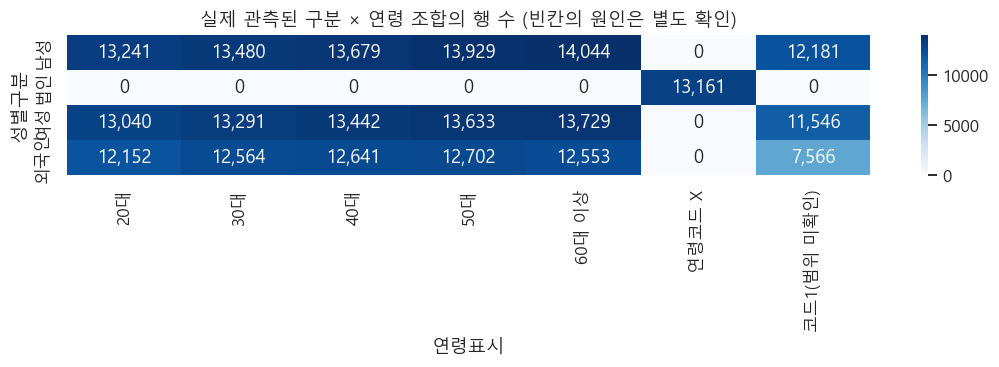

In [4]:
support['전체기간관측'] = support['관측월수'].eq(len(months))
table('00_region_month_support', support.sort_values(['관측월수'] + KEY), n=10)
monthly_audit = df.groupby('STRD_YYMM', observed=True).agg(행수=('AMT', 'size'),
    금액=('AMT', 'sum'), 건수=('CNT', 'sum')).reset_index()
monthly_regions = df[KEY + ['STRD_YYMM']].drop_duplicates().groupby('STRD_YYMM').size()
monthly_audit['지역수'] = monthly_audit['STRD_YYMM'].map(monthly_regions)
table('00_month_audit', monthly_audit, n=None)
print(f'분석 행: {len(df):,}; 지역: {len(support):,}; 월: {months}; 인코딩: {encoding_used}')
print('지역 정의:', REGION_DEFINITION)
print('외국인 정의:', FOREIGN_DEFINITION)
if not support['전체기간관측'].all():
    note('전체 기간에 걸쳐 관측되지 않은 지역이 있습니다. 시간 비교는 별도 공통 패널만 사용합니다.')
if ((df['GENDER_CD'] == '3') & df['AGE_CD'].isin(CONFIRMED_AGE_CODES)).any():
    note('외국인에도 연령코드가 관측됩니다. 외국인 지역·월·연령 보정 분석을 실행합니다.')

plt.figure(figsize=(10, 3.5))
sns.heatmap(combo, annot=True, fmt=',d', cmap='Blues')
plt.title('실제 관측된 구분 × 연령 조합의 행 수 (빈칸의 원인은 별도 확인)')
finish_figure('00_group_age_audit')


## 2. 돈의 비중과 결제의 비중은 같은가?

같은 업종이라도 전체 금액에서 차지하는 비중과 전체 건수에서 차지하는 비중은 다릅니다.
건수 비중이 높고 금액 비중이 낮으면, **이 표본에서 상대적으로 작은 금액의 결제가 많이 관측되는 업종**입니다.
이 결과는 소액 결제 혜택을 조사할 단서가 되지만 고객 수·소득·개인별 이용 빈도는 알려주지 않습니다.

분석 모집단: 내국인 코드 1·2 / 관측된 전체 연령 / 11개 업종. 외국인·법인 혼합을 피합니다.


[01_amount_vs_count] 전체 11행; 파일에는 모든 행 저장


,TPBUZ_NO,TPBUZ_NM,AMT,CNT,금액비중_pct,건수비중_pct,건수_금액_비중차_pp,건당결제금액
1,4010,편의점,"2,095,288,040,000.000","259,581,485.000",14.071,32.111,18.040,"8,071.793"
8,8006,서양음식,"1,635,284,450,000.000","148,357,326.000",10.982,18.352,7.370,"11,022.607"
10,8301,제과점,"412,594,150,000.000","32,596,070.000",2.771,4.032,1.261,"12,657.788"
9,8021,스넥,"497,538,240,000.000","31,009,379.000",3.341,3.836,0.495,"16,044.766"
5,8003,한정식,"1,194,310,000.000","14,829.000",0.008,0.002,-0.006,"80,538.809"
4,8002,갈비전문점,"8,573,070,000.000","111,362.000",0.058,0.014,-0.044,"76,983.801"
2,4020,슈퍼마켓,"2,236,492,760,000.000","116,553,651.000",15.020,14.418,-0.601,"19,188.526"
7,8005,중국음식,"441,635,410,000.000","15,627,203.000",2.966,1.933,-1.033,"28,260.682"
6,8004,일식회집,"437,658,500,000.000","8,707,925.000",2.939,1.077,-1.862,"50,259.792"
0,4004,대형할인점,"1,502,046,660,000.000","43,324,104.000",10.087,5.359,-4.728,"34,669.999"


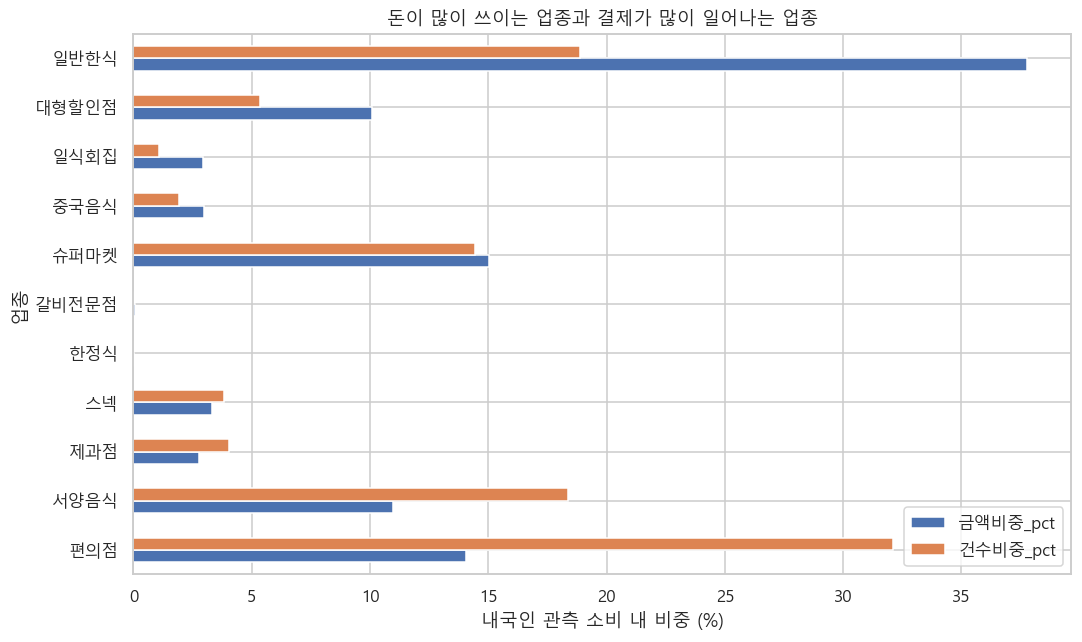

In [5]:
dom = df[df['GROUP'].eq('내국인')].copy()
if dom.empty:
    raise ValueError('내국인 코드 1·2가 없습니다. GENDER_CD 정의를 확인하세요.')
business = dom.groupby(['TPBUZ_NO', 'TPBUZ_NM'], observed=True)[['AMT', 'CNT']].sum().reset_index()
business['금액비중_pct'] = business['AMT'] / business['AMT'].sum() * 100
business['건수비중_pct'] = business['CNT'] / business['CNT'].sum() * 100
business['건수_금액_비중차_pp'] = business['건수비중_pct'] - business['금액비중_pct']
business['건당결제금액'] = business['AMT'] / business['CNT']
business = business.sort_values('건수_금액_비중차_pp', ascending=False)
table('01_amount_vs_count', business, n=None)

ax = business.set_index('TPBUZ_NM')[['금액비중_pct', '건수비중_pct']].plot.barh(figsize=(10, 6))
ax.set_xlabel('내국인 관측 소비 내 비중 (%)')
ax.set_ylabel('업종')
ax.set_title('돈이 많이 쓰이는 업종과 결제가 많이 일어나는 업종')
finish_figure('01_amount_vs_count')


## 3. 공통 비교 함수: 같은 조건으로 맞추어 비교하기

예를 들어 외국인이 슈퍼마켓 비중이 높은 지역에 많이 분포하면, 전국 합계에서는 차이가 커질 수 있습니다.
그래서 **같은 지역·같은 월 안에서** 집단별 업종 비중을 계산하고, 두 집단에 같은 가중치를 줍니다.
이 과정을 직접 표준화라고 합니다. 개인별 정보를 추정하는 작업은 아닙니다.

- **원자료 차이:** 선택된 모집단의 모든 관측 행에서 계산.
- **공통표본 차이:** 양쪽 집단·필요 업종이 관측되고 관측량 기준을 통과한 조합에서 계산.
- **구성보정 차이:** 그 공통표본에서 두 집단에 같은 지역·월 등의 가중치를 적용.

금액 비중 비교는 두 집단을 합친 금액, 건수 비중 비교는 합친 건수를 가중치로 사용합니다.
`보정후 차이 = Σ 공통가중치 × (집단1의 업종 비중 - 집단0의 업종 비중)`.

**공통표본 차이와 구성보정 차이**가 달라지는지 보세요. 원자료 차이와의 차이에는 분석 대상이 줄어든 영향도 섞입니다.
구성보정도 소득·선호·이동수단·BC 점유율 등의 영향을 제거하지 못하므로 인과효과가 아닙니다.

기본값은 필요한 업종이 모두 관측된 조합만 사용합니다. 이 때문에 대형할인점 등이 관측되지 않는 지역이 빠질 수 있습니다.
함께 저장되는 **집단별 금액·건수 포함률**이 낮으면 전국으로 일반화하지 마세요.


In [6]:
def standardized_mix(data, group_col, group0, group1, strata, categories,
                     min_cnt=MIN_STRATUM_CNT, require_complete=True):
    """group1 - group0의 관측 업종 비중 차이. 공통 조합·양쪽 집단에 동일 가중치 적용."""
    s = data[data[group_col].isin([group0, group1]) & data['BUCKET'].isin(categories)].copy()
    empty = {'comparison': pd.DataFrame(), 'coverage': pd.DataFrame(),
             'regional': pd.DataFrame(), 'matched': s.iloc[0:0].copy(), 'n_strata': 0}
    if s.empty or s[group_col].nunique() < 2:
        return empty
    g = s.groupby(strata + [group_col, 'BUCKET'], observed=True)[['AMT', 'CNT']].sum().reset_index()
    totals = g.groupby(strata + [group_col], observed=True).agg(
        AMT=('AMT', 'sum'), CNT=('CNT', 'sum'), n_bucket=('BUCKET', 'nunique')).reset_index()
    totals['ok'] = (totals['CNT'] >= min_cnt) & (totals['AMT'] > 0)
    if require_complete:
        totals['ok'] &= totals['n_bucket'].eq(len(categories))
    valid = totals[totals['ok']].groupby(strata, observed=True)[group_col].nunique()
    shared = valid[valid.eq(2)].reset_index()[strata]
    if shared.empty:
        return empty
    matched = s.merge(shared, on=strata, how='inner', validate='many_to_one')
    rows, cover, regional = [], [], []
    for group in [group0, group1]:
        original = s[s[group_col].eq(group)]
        retained = matched[matched[group_col].eq(group)]
        cover.append({'집단': group, '원자료건수': original['CNT'].sum(),
            '포함건수': retained['CNT'].sum(),
            '건수포함률_pct': retained['CNT'].sum() / original['CNT'].sum() * 100,
            '금액포함률_pct': retained['AMT'].sum() / original['AMT'].sum() * 100,
            '공통비교조합수': len(shared), '완전범주요구': require_complete})
    for metric in ['AMT', 'CNT']:
        pivots = {}
        for group in [group0, group1]:
            p = matched[matched[group_col].eq(group)].pivot_table(
                index=strata, columns='BUCKET', values=metric, aggfunc='sum', observed=True)
            p = p.reindex(columns=categories)
            # 완전 범주를 요구하는 주분석에서는 결측이 없음을 확인합니다.
            if require_complete and p.isna().any().any():
                raise AssertionError('완전범주 공통표본에 결측이 있습니다.')
            # require_complete=False는 관측되지 않은 범주를 0으로 간주하는 민감도 시나리오입니다.
            pivots[group] = p.fillna(0)
        p0 = pivots[group0].sort_index()
        p1 = pivots[group1].reindex(p0.index)
        t0, t1 = p0.sum(axis=1), p1.sum(axis=1)
        w = (t0 + t1) / (t0 + t1).sum()
        share0, share1 = p0.div(t0, axis=0), p1.div(t1, axis=0)
        std0, std1 = share0.mul(w, axis=0).sum(), share1.mul(w, axis=0).sum()
        raw0 = s[s[group_col].eq(group0)].groupby('BUCKET')[metric].sum().reindex(categories, fill_value=0)
        raw1 = s[s[group_col].eq(group1)].groupby('BUCKET')[metric].sum().reindex(categories, fill_value=0)
        raw0, raw1 = raw0 / raw0.sum(), raw1 / raw1.sum()
        match0, match1 = p0.sum() / t0.sum(), p1.sum() / t1.sum()
        for cat in categories:
            rows.append({'지표': metric, '업종묶음': cat, '기준집단': group0, '비교집단': group1,
                '원자료차이_pp': (raw1[cat] - raw0[cat]) * 100,
                '공통표본차이_pp': (match1[cat] - match0[cat]) * 100,
                '구성보정차이_pp': (std1[cat] - std0[cat]) * 100,
                '기준집단_보정비중_pct': std0[cat] * 100,
                '비교집단_보정비중_pct': std1[cat] * 100})
        if set(KEY).issubset(strata):
            dif = (share1 - share0).mul(t0 + t1, axis=0).reset_index()
            den = (t0 + t1).rename('_w').reset_index().groupby(KEY, observed=True)['_w'].sum()
            rg = dif.groupby(KEY, observed=True)[categories].sum().div(den, axis=0) * 100
            rg = rg.reset_index().melt(id_vars=KEY, var_name='업종묶음', value_name='구성보정차이')
            rg = rg.rename(columns={'구성보정차이': '구성보정차이_pp'})
            rg['지표'] = metric
            regional.append(rg)
    comparison = pd.DataFrame(rows)
    comparison['공통표본_보정후_방향반전'] = (
        comparison['공통표본차이_pp'] * comparison['구성보정차이_pp'] < -1e-10)
    return {'comparison': comparison, 'coverage': pd.DataFrame(cover),
            'regional': pd.concat(regional, ignore_index=True) if regional else pd.DataFrame(),
            'matched': matched, 'n_strata': len(shared)}

def show_mix(result, prefix, title):
    if result['comparison'].empty:
        note(f'{title}: 공통 비교조합이 없어 건너뜁니다. 정의·관측량·범주 포함 조건을 확인하세요.')
        return
    table(prefix + '_comparison', result['comparison'], n=None)
    table(prefix + '_coverage', result['coverage'], n=None)
    table(prefix + '_regional', result['regional'], n=8)
    draw = result['comparison'][result['comparison']['지표'].eq('AMT')].set_index('업종묶음')
    ax = draw[['원자료차이_pp', '공통표본차이_pp', '구성보정차이_pp']].plot.barh(figsize=(11, 5))
    ax.axvline(0, color='black', lw=1)
    ax.set_xlabel('비교집단 − 기준집단의 금액 비중 차이 (%p)')
    ax.set_ylabel('업종묶음'); ax.set_title(title)
    finish_figure(prefix)


## 4. 외국인 차이: 지역 탓인가, 같은 조건에서도 남는가?

**4A**는 내국인·외국인의 전체 연령을 사용해 지역·월을 맞춥니다.
**4B**는 코드가 확인된 20~60대 이상만 남기고 지역·월·연령을 맞춥니다.
4A와 4B는 모집단이 다르므로 두 결과를 인과적인 '연령 효과'로 빼서 해석하지 않습니다.
외국인의 성별이 따로 없으므로 성별까지 보정할 수는 없습니다.

읽는 예: 슈퍼마켓의 공통표본 차이가 +10%p, 보정 차이가 +2%p라면,
같은 비교조건에 동일한 가중치를 주었을 때 차이가 작아진 것입니다. +2%p도 선호·소득의 효과를 뜻하지 않습니다.


[02_foreign_region_month_comparison] 전체 12행; 파일에는 모든 행 저장


,지표,업종묶음,기준집단,비교집단,원자료차이_pp,공통표본차이_pp,구성보정차이_pp,기준집단_보정비중_pct,비교집단_보정비중_pct,공통표본_보정후_방향반전
0,AMT,일반한식,내국인,외국인,-12.285,-12.009,-11.404,37.356,25.952,False
1,AMT,서양음식,내국인,외국인,-0.753,-0.711,0.158,10.995,11.154,True
2,AMT,기타 음식점·제과,내국인,외국인,-1.469,-1.407,-1.491,12.110,10.619,False
3,AMT,슈퍼마켓,내국인,외국인,10.720,10.473,7.450,15.013,22.462,False
4,AMT,편의점,내국인,외국인,5.860,5.821,5.880,14.167,20.047,False
5,AMT,대형할인점,내국인,외국인,-2.073,-2.167,-0.593,10.359,9.766,False
6,CNT,일반한식,내국인,외국인,-6.450,-6.259,-6.120,18.597,12.476,False
7,CNT,서양음식,내국인,외국인,-4.278,-4.262,-2.799,18.338,15.539,False
8,CNT,기타 음식점·제과,내국인,외국인,-2.301,-2.275,-1.922,10.886,8.964,False
9,CNT,슈퍼마켓,내국인,외국인,8.136,8.040,5.757,14.411,20.168,False


[02_foreign_region_month_coverage] 전체 2행; 파일에는 모든 행 저장


,집단,원자료건수,포함건수,건수포함률_pct,금액포함률_pct,공통비교조합수,완전범주요구
0,내국인,"808,378,071.000","784,693,614.000",97.070,96.348,1178,True
1,외국인,"75,509,726.000","73,296,928.000",97.070,96.539,1178,True


[02_foreign_region_month_regional] 전체 2,364행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,업종묶음,구성보정차이_pp,지표
0,강원특별자치도,강릉시,일반한식,-10.881,AMT
1,강원특별자치도,동해시,일반한식,-10.670,AMT
2,강원특별자치도,삼척시,일반한식,-11.546,AMT
3,강원특별자치도,속초시,일반한식,-12.101,AMT
4,강원특별자치도,영월군,일반한식,-19.447,AMT
5,강원특별자치도,원주시,일반한식,-7.178,AMT
6,강원특별자치도,인제군,일반한식,-9.482,AMT
7,강원특별자치도,춘천시,일반한식,-8.983,AMT


C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:63: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
c:\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


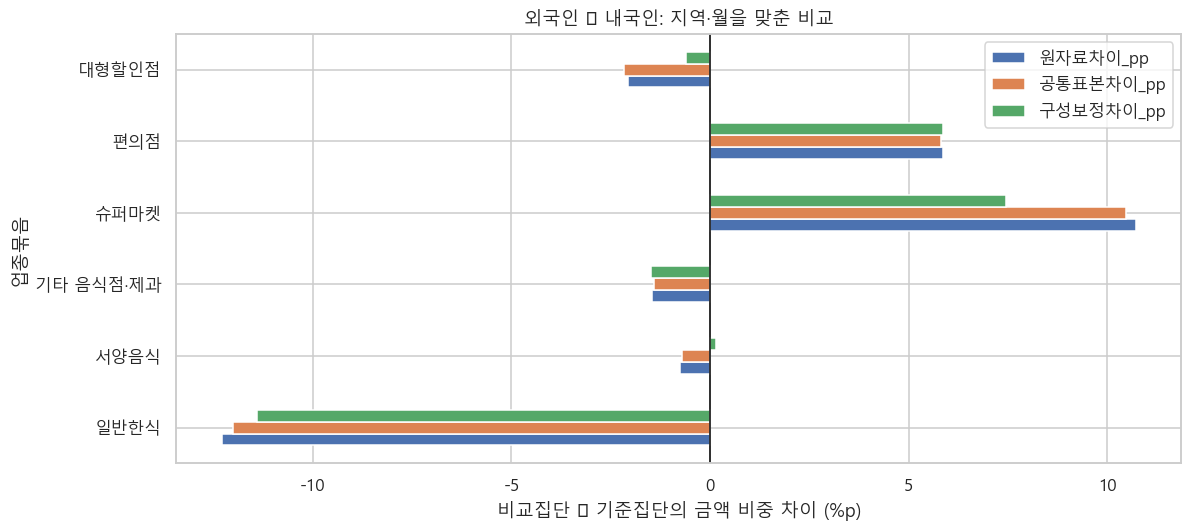

[03_foreign_region_month_age_comparison] 전체 12행; 파일에는 모든 행 저장


,지표,업종묶음,기준집단,비교집단,원자료차이_pp,공통표본차이_pp,구성보정차이_pp,기준집단_보정비중_pct,비교집단_보정비중_pct,공통표본_보정후_방향반전
0,AMT,일반한식,내국인,외국인,-12.161,-11.803,-7.799,37.315,29.516,False
1,AMT,서양음식,내국인,외국인,-0.756,-0.716,-0.901,11.036,10.135,False
2,AMT,기타 음식점·제과,내국인,외국인,-1.358,-1.278,-1.113,12.119,11.006,False
3,AMT,슈퍼마켓,내국인,외국인,10.744,10.433,7.061,14.915,21.975,False
4,AMT,편의점,내국인,외국인,5.595,5.522,2.843,14.167,17.010,False
5,AMT,대형할인점,내국인,외국인,-2.063,-2.159,-0.090,10.448,10.358,False
6,CNT,일반한식,내국인,외국인,-6.383,-6.141,-3.841,18.598,14.758,False
7,CNT,서양음식,내국인,외국인,-4.146,-4.122,-3.134,18.461,15.327,False
8,CNT,기타 음식점·제과,내국인,외국인,-2.166,-2.127,-1.224,10.883,9.660,False
9,CNT,슈퍼마켓,내국인,외국인,8.189,8.066,6.562,14.385,20.947,False


[03_foreign_region_month_age_coverage] 전체 2행; 파일에는 모든 행 저장


,집단,원자료건수,포함건수,건수포함률_pct,금액포함률_pct,공통비교조합수,완전범주요구
0,내국인,"791,885,360.000","763,732,940.000",96.445,95.712,5697,True
1,외국인,"72,961,528.000","70,294,731.000",96.345,95.841,5697,True


[03_foreign_region_month_age_regional] 전체 2,364행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,업종묶음,구성보정차이_pp,지표
0,강원특별자치도,강릉시,일반한식,-6.239,AMT
1,강원특별자치도,동해시,일반한식,-9.091,AMT
2,강원특별자치도,삼척시,일반한식,-8.326,AMT
3,강원특별자치도,속초시,일반한식,-7.403,AMT
4,강원특별자치도,영월군,일반한식,-11.812,AMT
5,강원특별자치도,원주시,일반한식,-5.551,AMT
6,강원특별자치도,인제군,일반한식,-6.985,AMT
7,강원특별자치도,춘천시,일반한식,-6.922,AMT


C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:63: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
c:\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


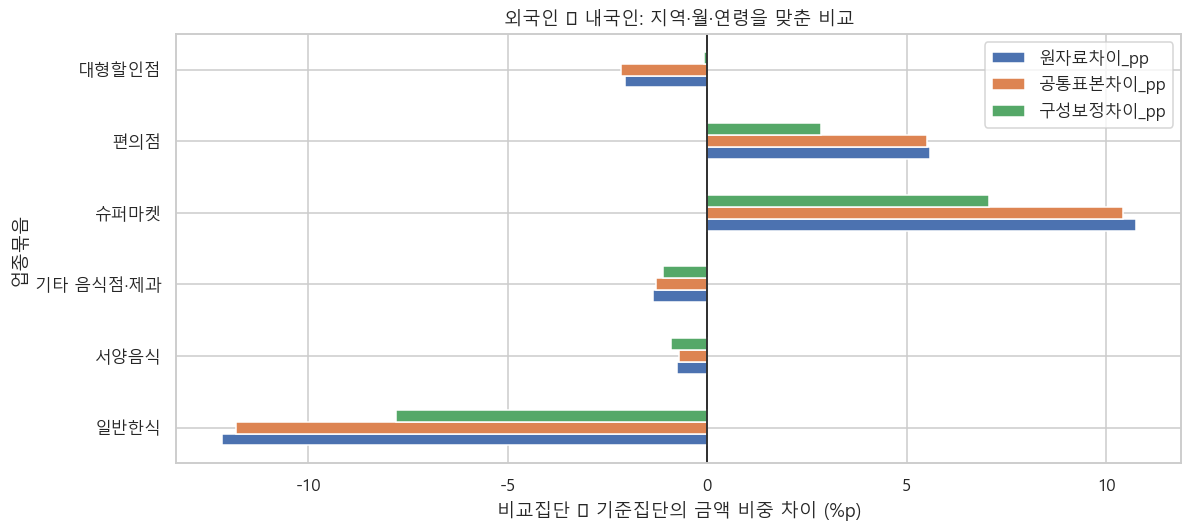

In [7]:
foreign_source = df[df['GROUP'].isin(['내국인', '외국인']) & df['BUCKET'].isin(BUCKETS)].copy()
foreign_region = standardized_mix(foreign_source, 'GROUP', '내국인', '외국인',
    KEY + ['STRD_YYMM'], BUCKETS)
show_mix(foreign_region, '02_foreign_region_month', '외국인 − 내국인: 지역·월을 맞춘 비교')

foreign_age_source = foreign_source[foreign_source['AGE_CD'].isin(CONFIRMED_AGE_CODES)].copy()
foreign_age = standardized_mix(foreign_age_source, 'GROUP', '내국인', '외국인',
    KEY + ['STRD_YYMM', 'AGE_CD'], BUCKETS)
show_mix(foreign_age, '03_foreign_region_month_age', '외국인 − 내국인: 지역·월·연령을 맞춘 비교')


## 5. 고령층 가설을 반증할 수 있게 비교하기

내국인 중 **60대 이상 vs 20~50대**를 비교합니다. 연령 미확인 코드 1과 외국인은 포함하지 않습니다.
분모는 **슈퍼마켓·편의점·대형할인점 3개 업종의 관측 금액 또는 건수 합계**입니다.
지역·월·성별을 맞추고, 두 연령집단이 겹치지 않도록 만듭니다.

편의점의 보정 차이가 양수인 지역뿐 아니라 **음수인 지역도 모두 저장**합니다.
양수 지역이 하나도 없으면 '현재 분석 조건에서 해당 가설이 지지되지 않음'이라고 출력합니다.
부호만으로 식품사막·건강 문제·경제적 빈곤을 판정하지 않습니다.


[04_age_retail_comparison] 전체 6행; 파일에는 모든 행 저장


,지표,업종묶음,기준집단,비교집단,원자료차이_pp,공통표본차이_pp,구성보정차이_pp,기준집단_보정비중_pct,비교집단_보정비중_pct,공통표본_보정후_방향반전
0,AMT,슈퍼마켓,20~50대,60대 이상,19.465,19.327,19.030,32.411,51.442,False
1,AMT,편의점,20~50대,60대 이상,-23.299,-23.328,-21.409,41.709,20.300,False
2,AMT,대형할인점,20~50대,60대 이상,3.834,4.001,2.379,25.880,28.258,False
3,CNT,슈퍼마켓,20~50대,60대 이상,23.469,23.444,21.942,22.788,44.730,False
4,CNT,편의점,20~50대,60대 이상,-28.480,-28.614,-26.068,67.464,41.395,False
5,CNT,대형할인점,20~50대,60대 이상,5.011,5.169,4.126,9.748,13.874,False


[04_age_retail_coverage] 전체 2행; 파일에는 모든 행 저장


,집단,원자료건수,포함건수,건수포함률_pct,금액포함률_pct,공통비교조합수,완전범주요구
0,20~50대,"312,461,866.000","304,755,221.000",97.534,97.215,2372,True
1,60대 이상,"97,261,179.000","94,655,139.000",97.321,97.026,2372,True


[04_age_retail_regional] 전체 1,188행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,업종묶음,구성보정차이_pp,지표
0,강원특별자치도,강릉시,슈퍼마켓,23.023,AMT
1,강원특별자치도,동해시,슈퍼마켓,18.282,AMT
2,강원특별자치도,삼척시,슈퍼마켓,16.754,AMT
3,강원특별자치도,속초시,슈퍼마켓,18.054,AMT
4,강원특별자치도,영월군,슈퍼마켓,21.299,AMT
5,강원특별자치도,원주시,슈퍼마켓,21.438,AMT
6,강원특별자치도,인제군,슈퍼마켓,23.075,AMT
7,강원특별자치도,춘천시,슈퍼마켓,19.085,AMT


C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:63: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
c:\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


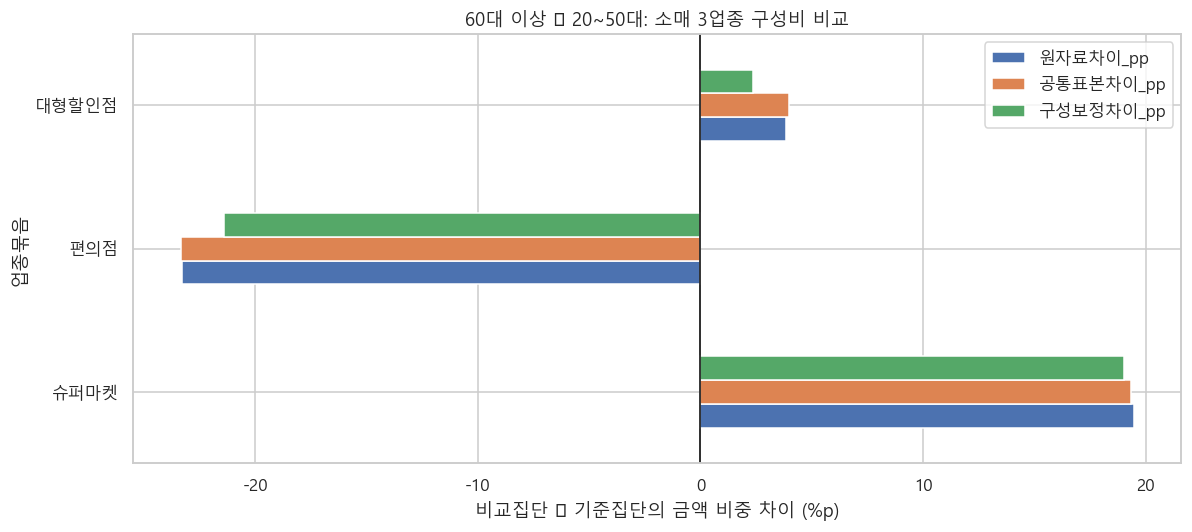

[04_age_cvs_signed_regions] 전체 198행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,업종묶음,구성보정차이_pp,지표,20~50대,60대 이상,관측량기준충족
40,경기도,여주시,편의점,-0.205,AMT,"729,501.000","206,187.000",True
30,경기도,수원시 장안구,편의점,-7.105,AMT,"1,801,022.000","542,575.000",True
51,경기도,하남시,편의점,-7.209,AMT,"1,894,386.000","531,519.000",True
35,경기도,안성시,편의점,-8.747,AMT,"1,717,792.000","348,127.000",True
10,강원특별자치도,홍천군,편의점,-9.173,AMT,"344,680.000","103,694.000",True
161,전라남도,광양시,편의점,-9.950,AMT,"931,231.000","209,611.000",True
106,부산광역시,기장군,편의점,-10.306,AMT,"1,373,895.000","391,072.000",True
111,부산광역시,북구,편의점,-11.094,AMT,"2,593,619.000","1,774,962.000",True
11,경기도,고양시 덕양구,편의점,-11.112,AMT,"2,478,394.000","789,353.000",True
153,인천광역시,동구,편의점,-11.433,AMT,"295,444.000","133,161.000",True


표시 기준 충족 198개 지역 중 양수 0개, 음수 198개
현재 공통표본·비교조건에서 고령층 편의점 비중이 더 높다는 가설을 지지하는 지역은 없습니다.


C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:63: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\정서영\AppData\Local\Temp\ipykernel_42940\2577936893.py:65: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
c:\anaconda\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


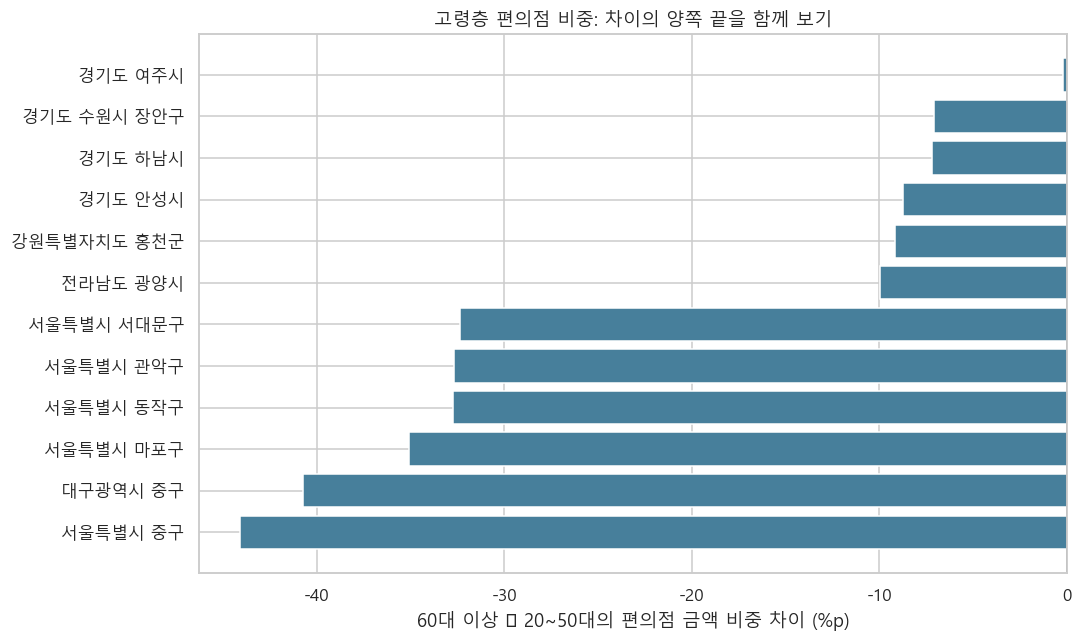

In [8]:
age_source = dom[dom['AGE_CD'].isin(CONFIRMED_AGE_CODES) & dom['BUCKET'].isin(RETAIL3)].copy()
age_source['AGE_GROUP'] = np.where(age_source['AGE_CD'].eq('6'), '60대 이상', '20~50대')
old_mix = standardized_mix(age_source, 'AGE_GROUP', '20~50대', '60대 이상',
    KEY + ['STRD_YYMM', 'GENDER_CD'], RETAIL3)
show_mix(old_mix, '04_age_retail', '60대 이상 − 20~50대: 소매 3업종 구성비 비교')

old_regions = pd.DataFrame()
if not old_mix['regional'].empty:
    old_regions = old_mix['regional'].query("지표 == 'AMT' and 업종묶음 == '편의점'").copy()
    old_counts = old_mix['matched'].groupby(KEY + ['AGE_GROUP'], observed=True)['CNT'].sum().unstack()
    old_regions = old_regions.merge(old_counts.reset_index(), on=KEY, validate='one_to_one')
    old_regions['관측량기준충족'] = old_regions[['20~50대', '60대 이상']].min(axis=1) >= MIN_REGION_CNT
    table('04_age_cvs_signed_regions', old_regions.sort_values('구성보정차이_pp', ascending=False))
    eligible_old = old_regions[old_regions['관측량기준충족']]
    n_pos = int((eligible_old['구성보정차이_pp'] > 1e-9).sum())
    n_neg = int((eligible_old['구성보정차이_pp'] < -1e-9).sum())
    print(f'표시 기준 충족 {len(eligible_old)}개 지역 중 양수 {n_pos}개, 음수 {n_neg}개')
    if len(eligible_old) and n_pos == 0:
        note('현재 공통표본·비교조건에서 고령층 편의점 비중이 더 높다는 가설을 지지하는 지역은 없습니다.')
    plot_old = pd.concat([eligible_old.nlargest(6, '구성보정차이_pp'),
                          eligible_old.nsmallest(6, '구성보정차이_pp')]).drop_duplicates(KEY)
    if not plot_old.empty:
        plot_old = plot_old.sort_values('구성보정차이_pp')
        plt.figure(figsize=(10, 6))
        plt.barh(region_labels(plot_old), plot_old['구성보정차이_pp'],
                 color=np.where(plot_old['구성보정차이_pp'] >= 0, '#c75d45', '#477f9b'))
        plt.axvline(0, color='black', lw=1)
        plt.xlabel('60대 이상 − 20~50대의 편의점 금액 비중 차이 (%p)')
        plt.title('고령층 편의점 비중: 차이의 양쪽 끝을 함께 보기')
        finish_figure('04_age_cvs_both_directions')


## 6. 지역 특성: 소비층 구성이 같아도 업종의 차이가 남는가?

단순히 슈퍼마켓 비중이 높은 지역을 뽑으면 고령층 구성 차이를 지역 특성으로 착각할 수 있습니다.
여기서는 **월·성별·연령별 결제건수 구성**을 고려한 기대 건수를 계산합니다.

각 지역의 비교 기준은 **그 지역을 제외한 나머지 지역**입니다.

`기대 업종 건수 = Σ [이 지역의 월·성별·연령별 전체 건수 × 다른 지역의 같은 조건에서의 업종 비중]`

`관측/기대 비율 = 실제 업종 건수 ÷ 기대 업종 건수`

1.3이면 같은 소비층 구성을 기준으로 기대한 것보다 관측 건수가 30% 많다는 뜻입니다.
해당 업종의 창업 성공률·수익성·충족되지 않은 수요를 의미하지 않습니다.
월·성별·연령별로 6개 업종묶음이 모두 관측된 조합만 사용하며 제외 비율을 출력합니다.


지역 기대건수 분석의 결제건수 포함률: 97.1% (확인 연령 내국인·6묶음 기준)
[05_region_contextual_lift] 전체 1,188행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,BUCKET,관측건수,기대건수,관측_기대_비율,분석지역_총건수,관측량기준충족
667,부산광역시,북구,대형할인점,"2,267,315.000","420,051.367",5.398,"6,932,598.000",True
181,경기도,수원시 장안구,대형할인점,"625,635.000","215,626.980",2.901,"3,897,240.000",True
307,경기도,하남시,대형할인점,"675,373.000","236,327.746",2.858,"4,204,260.000",True
496,경상북도,청도군,일반한식,"361,619.000","134,038.762",2.698,"675,502.000",True
1084,충청남도,공주시,일반한식,"805,666.000","322,711.240",2.497,"1,672,206.000",True
1042,전북특별자치도,임실군,일반한식,"141,466.000","57,057.652",2.479,"285,752.000",True
67,경기도,고양시 덕양구,대형할인점,"818,486.000","345,308.034",2.370,"6,099,758.000",True
241,경기도,여주시,대형할인점,"196,425.000","83,383.321",2.356,"1,487,040.000",True
763,서울특별시,금천구,대형할인점,"638,969.000","277,805.288",2.300,"5,212,825.000",True
38,강원특별자치도,인제군,서양음식,"86,727.000","37,838.028",2.292,"237,480.000",True


[05_supermarket_contextual_lift] 전체 198행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,BUCKET,관측건수,기대건수,관측_기대_비율,분석지역_총건수,관측량기준충족
579,대구광역시,서구,슈퍼마켓,"1,243,927.000","558,422.739",2.228,"3,404,099.000",True
525,광주광역시,남구,슈퍼마켓,"931,599.000","474,930.194",1.962,"3,166,362.000",True
429,경상북도,경산시,슈퍼마켓,"1,226,493.000","696,435.795",1.761,"4,770,196.000",True
519,광주광역시,광산구,슈퍼마켓,"1,701,587.000","988,068.978",1.722,"7,174,050.000",True
537,광주광역시,북구,슈퍼마켓,"1,868,245.000","1,085,729.956",1.721,"7,545,405.000",True
141,경기도,부천시 오정구,슈퍼마켓,"618,770.000","364,974.456",1.695,"2,290,622.000",True
561,대구광역시,달성군,슈퍼마켓,"1,087,611.000","659,602.537",1.649,"4,366,190.000",True
555,대구광역시,달서구,슈퍼마켓,"2,579,072.000","1,573,729.150",1.639,"10,340,291.000",True
1035,전북특별자치도,익산시,슈퍼마켓,"655,580.000","408,623.322",1.604,"2,753,331.000",True
483,경상북도,영천시,슈퍼마켓,"294,931.000","185,747.583",1.588,"1,169,323.000",True


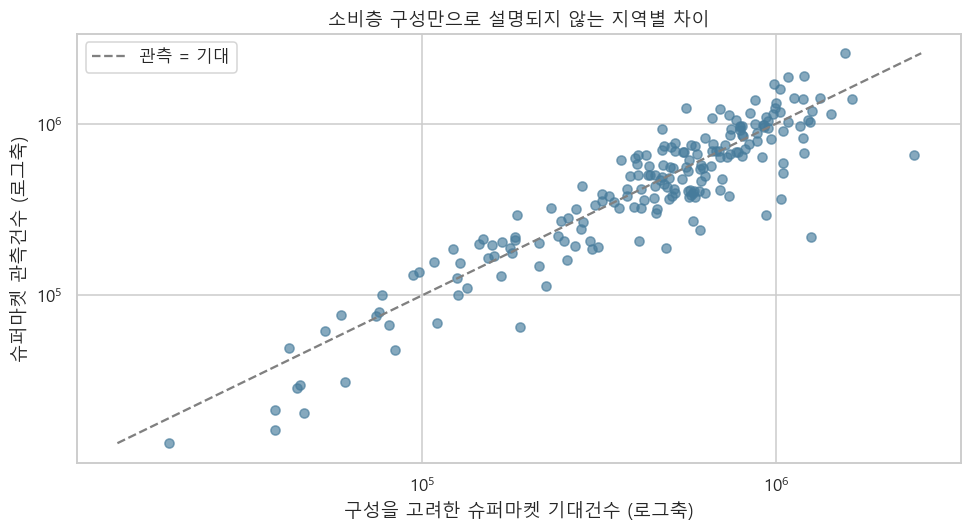

In [9]:
def contextual_region_lift(data, categories, min_cnt=MIN_STRATUM_CNT):
    strata = ['STRD_YYMM', 'GENDER_CD', 'AGE_CD']
    s = data[data['BUCKET'].isin(categories)].copy()
    g = s.groupby(KEY + strata + ['BUCKET'], observed=True)['CNT'].sum().reset_index()
    totals = g.groupby(KEY + strata, observed=True).agg(
        REG_N=('CNT', 'sum'), K=('BUCKET', 'nunique')).reset_index()
    ok = totals[(totals['REG_N'] >= min_cnt) & totals['K'].eq(len(categories))]
    g = g.merge(ok[KEY + strata + ['REG_N']], on=KEY + strata, validate='many_to_one')
    if g.empty:
        return pd.DataFrame(), 0.0
    national = g.groupby(strata + ['BUCKET'], observed=True)['CNT'].sum().rename('NAT_BUCKET').reset_index()
    nat_total = g.groupby(strata, observed=True)['CNT'].sum().rename('NAT_N').reset_index()
    g = g.merge(national, on=strata + ['BUCKET'], validate='many_to_one').merge(
        nat_total, on=strata, validate='many_to_one')
    g = g[g['NAT_N'] > g['REG_N']].copy()
    if g.empty:
        return pd.DataFrame(), 0.0
    g['EXPECT'] = g['REG_N'] * (g['NAT_BUCKET'] - g['CNT']) / (g['NAT_N'] - g['REG_N'])
    out = g.groupby(KEY + ['BUCKET'], observed=True).agg(
        관측임시=('CNT', 'sum'), EXPECT=('EXPECT', 'sum')).reset_index().rename(columns={'관측임시': '관측건수'})
    out['기대건수'] = out.pop('EXPECT')
    out['관측_기대_비율'] = out['관측건수'] / out['기대건수'].replace(0, np.nan)
    out['분석지역_총건수'] = out.groupby(KEY, observed=True)['관측건수'].transform('sum')
    out['관측량기준충족'] = out['분석지역_총건수'] >= MIN_REGION_CNT
    return out, float(g['CNT'].sum() / s['CNT'].sum() * 100) if len(s) else 0.0

lift_source = dom[dom['AGE_CD'].isin(CONFIRMED_AGE_CODES)].copy()
region_lift, lift_coverage = contextual_region_lift(lift_source, BUCKETS)
print(f'지역 기대건수 분석의 결제건수 포함률: {lift_coverage:.1f}% (확인 연령 내국인·6묶음 기준)')
if region_lift.empty:
    note('지역 기대건수 분석: 공통조건의 다른 지역 비교표본이 부족해 건너뜁니다.')
else:
    table('05_region_contextual_lift', region_lift.sort_values('관측_기대_비율', ascending=False))
    view_lift = region_lift[region_lift['관측량기준충족'] & region_lift['BUCKET'].eq('슈퍼마켓')]
    table('05_supermarket_contextual_lift', view_lift.sort_values('관측_기대_비율', ascending=False))
    plt.figure(figsize=(9, 5))
    plt.scatter(view_lift['기대건수'], view_lift['관측건수'], alpha=.65, color='#467b9b')
    if len(view_lift):
        lo = float(view_lift[['기대건수', '관측건수']].min().min())
        hi = float(view_lift[['기대건수', '관측건수']].max().max())
        plt.plot([lo, hi], [lo, hi], '--', color='gray', label='관측 = 기대')
        plt.xscale('log'); plt.yscale('log'); plt.legend()
    plt.xlabel('구성을 고려한 슈퍼마켓 기대건수 (로그축)')
    plt.ylabel('슈퍼마켓 관측건수 (로그축)')
    plt.title('소비층 구성만으로 설명되지 않는 지역별 차이')
    finish_figure('05_region_contextual_lift')


## 7. 같은 집계조합에서 본 금액 변화: 건수가 늘었나, 건당 금액이 늘었나?

기본 비교는 **1~3월 vs 4~6월**입니다. 두 기간의 일수를 각각 반영합니다.
지역·구분·연령·업종 조합이 선택한 **모든 월**에 있는 행만 사용합니다.
행정구역명 변경 등으로 시계열이 끊긴 조합은 공통 패널에 들어가지 않습니다.

`일평균 결제금액 = 일평균 결제건수 × 건당 결제금액`

따라서 로그 변화는 정확히 두 요소로 나뉩니다.
`log(금액비율) = log(건수비율) + log(건당금액비율)`

여기에 **같은 업종의 다른 지역 변화**를 빼 공통 움직임과 비교합니다.
로그 차이×100은 로그 포인트이며 일반적인 증가율 % 또는 비율 차이 %p와 다릅니다.
그래프는 로그 포인트, 원자료 증가율은 별도 열로 저장합니다.
이 비교는 계절조정·물가조정이 아니며, 두 기간의 관측 차이를 보여줄 뿐입니다.


[06_period_coverage] 전체 1행; 파일에는 모든 행 저장


,원자료건수,공통패널건수,공통조합수,공통패널건수포함률_pct
0,"808,378,071.000","808,322,530.000",26018,99.993


[06_matched_period_decomposition] 전체 2,320행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,TPBUZ_NO,TPBUZ_NM,AMT_A,AMT_B,CNT_A,CNT_B,REST_AMT_A,REST_AMT_B,...,UNIT_A,UNIT_B,일평균금액변화_pct,금액_상대변화_logpt,일평균건수변화_pct,건수_상대변화_logpt,건당금액_상대변화_logpt,분해잔차,관측량기준충족,상대방향
939,경상북도,울릉군,8006,서양음식,"69,080,000.000","228,950,000.000","3,540.000","11,134.000","791,278,890,000.000","843,703,730,000.000",...,"19,514.124","20,563.140",227.785,113.409,211.064,101.540,11.868,0.000,True,금액·건수 모두 상대상승
1164,대전광역시,유성구,8002,갈비전문점,"25,790,000.000","83,680,000.000",682.000,"2,198.000","3,690,180,000.000","3,999,610,000.000",...,"37,815.249","38,070.974",220.901,109.649,218.746,110.784,-1.135,0.000,False,금액·건수 모두 상대상승
937,경상북도,울릉군,8001,일반한식,"408,720,000.000","1,128,900,000.000","5,614.000","16,748.000","2,715,130,810,000.000","2,905,564,710,000.000",...,"72,803.705","67,405.063",173.169,94.818,195.047,101.131,-6.313,-0.000,True,금액·건수 모두 상대상승
2183,충청남도,태안군,8004,일식회집,"185,020,000.000","447,120,000.000","1,607.000","3,523.000","213,545,260,000.000","222,693,840,000.000",...,"115,133.790","126,914.561",139.005,84.041,116.819,69.983,14.058,-0.000,True,금액·건수 모두 상대상승
1640,인천광역시,강화군,8002,갈비전문점,"4,350,000.000","9,620,000.000",142.000,322.000,"3,711,620,000.000","4,073,670,000.000",...,"30,633.803","29,875.776",118.719,70.059,124.269,73.090,-3.031,0.000,False,금액·건수 모두 상대상승
952,경상북도,의성군,8004,일식회집,"5,960,000.000","11,980,000.000",127.000,208.000,"213,724,320,000.000","223,128,980,000.000",...,"46,929.134","57,596.154",98.798,65.511,61.980,40.786,24.724,0.000,False,금액·건수 모두 상대상승
940,경상북도,울릉군,8021,스넥,"35,600,000.000","74,980,000.000","1,021.000","2,650.000","232,897,170,000.000","264,444,150,000.000",...,"34,867.777","28,294.340",108.303,61.784,156.697,84.983,-23.198,0.000,True,금액·건수 모두 상대상승
1714,인천광역시,옹진군,8004,일식회집,"69,120,000.000","133,280,000.000",829.000,"1,214.000","213,661,160,000.000","223,007,680,000.000",...,"83,377.563","109,785.832",90.705,61.379,44.832,29.602,31.777,-0.000,False,금액·건수 모두 상대상승
938,경상북도,울릉군,8005,중국음식,"32,970,000.000","59,230,000.000",876.000,"1,412.000","222,943,450,000.000","218,479,330,000.000",...,"37,636.986","41,947.592",77.674,60.606,59.416,46.280,14.326,-0.000,False,금액·건수 모두 상대상승
1826,전라남도,신안군,8004,일식회집,"64,890,000.000","116,360,000.000",837.000,"1,208.000","213,665,390,000.000","223,024,600,000.000",...,"77,526.882","96,324.503",77.348,54.112,42.739,28.146,25.967,-0.000,False,금액·건수 모두 상대상승


[06_amount_up_count_down] 전체 121행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,TPBUZ_NO,TPBUZ_NM,AMT_A,AMT_B,CNT_A,CNT_B,REST_AMT_A,REST_AMT_B,...,UNIT_A,UNIT_B,일평균금액변화_pct,금액_상대변화_logpt,일평균건수변화_pct,건수_상대변화_logpt,건당금액_상대변화_logpt,분해잔차,관측량기준충족,상대방향
903,경상북도,영양군,8001,일반한식,"344,090,000.000","428,330,000.000","8,748.000","9,120.000","2,715,195,440,000.000","2,906,265,280,000.000",...,"39,333.562","46,966.009",23.114,15.099,3.107,-4.020,19.118,0.000,True,금액 상대상승·건수 상대하락
776,경상남도,하동군,8006,서양음식,"276,970,000.000","329,210,000.000","21,468.000","24,053.000","791,071,000,000.000","843,603,470,000.000",...,"12,901.528","13,686.858",17.555,10.849,10.810,-1.687,12.536,-0.000,True,금액 상대상승·건수 상대하락
951,경상북도,의성군,8001,일반한식,"1,282,980,000.000","1,488,320,000.000","53,108.000","56,334.000","2,714,256,550,000.000","2,905,205,290,000.000",...,"24,157.942","26,419.569",14.730,8.048,4.909,-2.288,10.336,0.000,True,금액 상대상승·건수 상대하락
1855,전라남도,영암군,8301,제과점,"80,660,000.000","83,670,000.000","5,198.000","5,268.000","208,956,710,000.000","203,383,350,000.000",...,"15,517.507","15,882.688",2.592,6.367,0.233,-1.737,8.104,-0.000,True,금액 상대상승·건수 상대하락
1907,전라남도,화순군,8004,일식회집,"62,470,000.000","69,310,000.000","1,083.000","1,105.000","213,667,810,000.000","223,071,650,000.000",...,"57,682.364","62,723.982",9.730,6.083,0.910,-6.541,12.624,0.000,True,금액 상대상승·건수 상대하락
89,강원특별자치도,인제군,8006,서양음식,"614,250,000.000","692,410,000.000","60,562.000","68,302.000","790,733,720,000.000","843,240,270,000.000",...,"10,142.499","10,137.478",11.486,5.549,11.541,-1.030,6.579,-0.000,True,금액 상대상승·건수 상대하락
25,강원특별자치도,동해시,8006,서양음식,"1,270,790,000.000","1,428,420,000.000","100,051.000","112,351.000","790,077,180,000.000","842,504,260,000.000",...,"12,701.422","12,713.906",11.169,5.268,11.060,-1.464,6.732,-0.000,True,금액 상대상승·건수 상대하락
1052,대구광역시,군위군,8006,서양음식,"581,660,000.000","652,530,000.000","58,951.000","67,085.000","790,766,310,000.000","843,280,150,000.000",...,"9,866.839","9,726.914",10.951,5.067,12.547,-0.131,5.198,0.000,True,금액 상대상승·건수 상대하락
1413,서울특별시,금천구,8004,일식회집,"667,030,000.000","728,870,000.000","21,624.000","23,472.000","213,063,250,000.000","222,412,090,000.000",...,"30,846.744","31,052.744",8.070,4.572,7.353,-0.352,4.924,0.000,True,금액 상대상승·건수 상대하락
614,경상남도,거창군,8301,제과점,"123,220,000.000","125,520,000.000","8,151.000","8,087.000","208,914,150,000.000","203,341,500,000.000",...,"15,117.164","15,521.207",0.747,4.553,-1.875,-3.864,8.417,0.000,True,금액 상대상승·건수 상대하락


두 기간 모두 건수 기준을 충족한 2194개 지역·업종 중 금액 상대상승/건수 상대하락: 121개


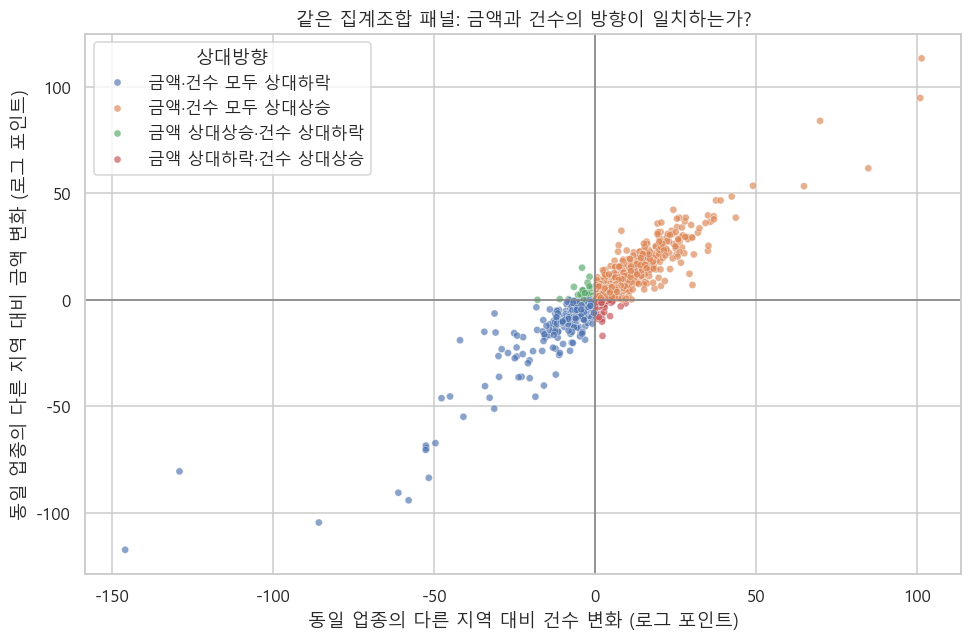

In [10]:
def matched_period_decomposition(data, period_a, period_b):
    empty = pd.DataFrame()
    a, b = list(dict.fromkeys(period_a)), list(dict.fromkeys(period_b))
    if not a or not b or set(a) & set(b):
        raise ValueError('기간 A와 B는 비어 있지 않고 서로 겹치지 않아야 합니다.')
    chosen = a + b
    if not set(chosen).issubset(set(data['STRD_YYMM'])):
        note('선택 기간의 월이 원본에 모두 없어 기간 비교를 건너뜁니다. PERIOD_A/B를 확인하세요.')
        return empty, {}
    unit_key = KEY + ['GENDER_CD', 'AGE_CD', 'TPBUZ_NO']
    s = data[data['STRD_YYMM'].isin(chosen)].copy()
    n_months = s.groupby(unit_key, observed=True)['STRD_YYMM'].nunique()
    shared = n_months[n_months.eq(len(chosen))].reset_index()[unit_key]
    panel = s.merge(shared, on=unit_key, how='inner', validate='many_to_one')
    coverage = {'원자료건수': float(s['CNT'].sum()), '공통패널건수': float(panel['CNT'].sum()),
        '공통조합수': len(shared), '공통패널건수포함률_pct': float(panel['CNT'].sum() / s['CNT'].sum() * 100)}
    if panel.empty:
        return empty, coverage
    panel['PERIOD'] = np.where(panel['STRD_YYMM'].isin(a), 'A', 'B')
    p = panel.groupby(KEY + ['TPBUZ_NO', 'TPBUZ_NM', 'PERIOD'], observed=True)[['AMT', 'CNT']].sum().unstack('PERIOD')
    p.columns = [f'{m}_{t}' for m, t in p.columns]
    p = p.reset_index()
    # 비교 지역을 제외한 같은 업종. 비교 집계에는 표시 기준 미달 지역도 포함합니다.
    for col in ['AMT_A', 'AMT_B', 'CNT_A', 'CNT_B']:
        p['REST_' + col] = p.groupby('TPBUZ_NO', observed=True)[col].transform('sum') - p[col]
    needed = ['AMT_A', 'AMT_B', 'CNT_A', 'CNT_B', 'REST_AMT_A', 'REST_AMT_B', 'REST_CNT_A', 'REST_CNT_B']
    p = p[p[needed].gt(0).all(axis=1)].copy()
    if p.empty:
        return empty, coverage
    days_a = sum(pd.Period(m, freq='M').days_in_month for m in a)
    days_b = sum(pd.Period(m, freq='M').days_in_month for m in b)
    p['UNIT_A'], p['UNIT_B'] = p['AMT_A'] / p['CNT_A'], p['AMT_B'] / p['CNT_B']
    for measure in ['AMT', 'CNT']:
        ratio = (p[measure + '_B'] / days_b) / (p[measure + '_A'] / days_a)
        rest_ratio = (p['REST_' + measure + '_B'] / days_b) / (p['REST_' + measure + '_A'] / days_a)
        p[measure + '_일평균변화_pct'] = (ratio - 1) * 100
        p[measure + '_상대로그포인트'] = (np.log(ratio) - np.log(rest_ratio)) * 100
    unit_ratio = p['UNIT_B'] / p['UNIT_A']
    rest_unit_ratio = (p['REST_AMT_B'] / p['REST_CNT_B']) / (p['REST_AMT_A'] / p['REST_CNT_A'])
    p['UNIT_상대로그포인트'] = (np.log(unit_ratio) - np.log(rest_unit_ratio)) * 100
    p = p.rename(columns={'AMT_일평균변화_pct': '일평균금액변화_pct', 'CNT_일평균변화_pct': '일평균건수변화_pct',
        'AMT_상대로그포인트': '금액_상대변화_logpt', 'CNT_상대로그포인트': '건수_상대변화_logpt',
        'UNIT_상대로그포인트': '건당금액_상대변화_logpt'})
    p['분해잔차'] = p['금액_상대변화_logpt'] - p['건수_상대변화_logpt'] - p['건당금액_상대변화_logpt']
    if not np.allclose(p['분해잔차'], 0, atol=1e-8):
        raise AssertionError('금액 = 건수 × 건당금액 분해 검증 실패')
    p['관측량기준충족'] = p[['CNT_A', 'CNT_B']].min(axis=1) >= MIN_PERIOD_CNT
    p['상대방향'] = np.select([
        (p['금액_상대변화_logpt'] >= 0) & (p['건수_상대변화_logpt'] >= 0),
        (p['금액_상대변화_logpt'] >= 0) & (p['건수_상대변화_logpt'] < 0),
        (p['금액_상대변화_logpt'] < 0) & (p['건수_상대변화_logpt'] >= 0)],
        ['금액·건수 모두 상대상승', '금액 상대상승·건수 상대하락', '금액 상대하락·건수 상대상승'],
        default='금액·건수 모두 상대하락')
    return p, coverage

periods, period_coverage = matched_period_decomposition(dom, PERIOD_A, PERIOD_B)
if period_coverage:
    table('06_period_coverage', pd.DataFrame([period_coverage]), n=None)
if periods.empty:
    note('기간 분해에 필요한 공통 집계조합 또는 다른 지역 비교표본이 부족합니다.')
else:
    table('06_matched_period_decomposition', periods.sort_values('금액_상대변화_logpt', ascending=False))
    qualified = periods[periods['관측량기준충족']]
    split = qualified[qualified['상대방향'].eq('금액 상대상승·건수 상대하락')]
    table('06_amount_up_count_down', split.sort_values('금액_상대변화_logpt', ascending=False))
    print(f'두 기간 모두 건수 기준을 충족한 {len(qualified)}개 지역·업종 중 금액 상대상승/건수 상대하락: {len(split)}개')
    plt.figure(figsize=(9, 6))
    sns.scatterplot(data=qualified, x='건수_상대변화_logpt', y='금액_상대변화_logpt',
                    hue='상대방향', alpha=.65, s=22)
    plt.axhline(0, color='gray', lw=1); plt.axvline(0, color='gray', lw=1)
    plt.xlabel('동일 업종의 다른 지역 대비 건수 변화 (로그 포인트)')
    plt.ylabel('동일 업종의 다른 지역 대비 금액 변화 (로그 포인트)')
    plt.title('같은 집계조합 패널: 금액과 건수의 방향이 일치하는가?')
    finish_figure('06_amount_count_quadrants')


## 8. 후속 조사 지역: 비중·규모·월별 관측을 함께 보기

외국인 비중이 높다는 이유만으로 금융서비스가 부족하거나 관광객이 많다고 결론 내리지 않습니다.
이 표는 **어느 지역부터 외부 자료를 조사할지** 고르는 자료입니다.

분모는 법인을 제외한 **내국인+외국인의 관측 소비**입니다. 기존 EDA의 법인 포함 분모와 값이 달라질 수 있습니다.
외국인 행이 없는 지역은 0으로 채우지 않고 별도 관측상태로 남깁니다.
월별 외국인 비중의 표준편차는 '관측 변동'이며 정착도·재방문율·안정적 고객 비율이 아닙니다.

금액 비중 순위뿐 아니라 절대 결제건수도 보고 지역을 선정하세요. 카드 이용이 적은 금융취약지역이 이 표에서 빠질 수 있으므로
지원 우선순위의 최종 분모는 등록외국인 등 외부 인구자료로 검증해야 합니다.


[07_foreign_monthly_observation] 전체 1,530행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,STRD_YYMM,AMT_내국인,AMT_외국인,CNT_내국인,CNT_외국인,쌍관측
0,강원특별자치도,강릉시,202601,"13,334,020,000.000","710,900,000.000","539,055.000","34,853.000",True
1,강원특별자치도,강릉시,202602,"12,758,440,000.000","657,400,000.000","514,570.000","31,540.000",True
2,강원특별자치도,강릉시,202603,"11,426,400,000.000","651,480,000.000","501,251.000","34,832.000",True
3,강원특별자치도,강릉시,202604,"12,025,720,000.000","645,990,000.000","528,457.000","36,382.000",True
4,강원특별자치도,강릉시,202605,"14,407,730,000.000","791,720,000.000","612,832.000","44,319.000",True


[07_foreign_region_candidates] 전체 255행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,쌍관측월수,외국인금액,내국인금액,외국인건수,내국인건수,월비중중앙값_pct,월비중표준편차_pp,외국인금액비중_pct,외국인건수비중_pct,전체월_쌍관측,외국인건수기준충족
224,제주특별자치도,제주시,6,"119,239,370,000.000","208,514,560,000.000","5,938,783.000","9,807,241.000",36.699,1.000,36.381,37.716,True,True
200,전라남도,영암군,6,"5,241,480,000.000","11,046,660,000.000","328,405.000","539,639.000",32.205,1.131,32.180,37.833,True,True
223,제주특별자치도,서귀포시,6,"37,624,060,000.000","89,082,970,000.000","1,689,970.000","3,610,439.000",30.078,1.230,29.694,31.884,True,True
246,충청북도,음성군,6,"10,048,750,000.000","27,278,570,000.000","615,000.000","1,450,272.000",26.617,0.718,26.921,29.778,True,True
62,경기도,화성시 만세구,6,"28,376,910,000.000","82,220,730,000.000","1,622,621.000","4,316,628.000",25.575,0.420,25.658,27.320,True,True
249,충청북도,진천군,6,"6,853,250,000.000","21,982,570,000.000","404,394.000","1,094,020.000",23.695,0.641,23.766,26.988,True,True
41,경기도,안산시 단원구,6,"34,138,790,000.000","125,489,940,000.000","1,987,549.000","6,592,202.000",21.233,0.568,21.386,23.166,True,True
89,경상북도,고령군,6,"1,694,460,000.000","7,344,550,000.000","78,144.000","383,725.000",18.810,0.710,18.746,16.919,True,True
40,경기도,시흥시,6,"36,425,840,000.000","160,114,280,000.000","1,983,348.000","8,309,203.000",18.474,0.458,18.534,19.270,True,True
234,충청남도,아산시,6,"18,424,440,000.000","92,548,000,000.000","1,150,846.000","4,976,138.000",16.573,0.269,16.603,18.783,True,True


[07_foreign_candidates_by_volume] 전체 254행; 파일에는 모든 행 저장


,SIDO_NM,CCG_NM,쌍관측월수,외국인금액,내국인금액,외국인건수,내국인건수,월비중중앙값_pct,월비중표준편차_pp,외국인금액비중_pct,외국인건수비중_pct,전체월_쌍관측,외국인건수기준충족
224,제주특별자치도,제주시,6,"119,239,370,000.000","208,514,560,000.000","5,938,783.000","9,807,241.000",36.699,1.000,36.381,37.716,True,True
41,경기도,안산시 단원구,6,"34,138,790,000.000","125,489,940,000.000","1,987,549.000","6,592,202.000",21.233,0.568,21.386,23.166,True,True
40,경기도,시흥시,6,"36,425,840,000.000","160,114,280,000.000","1,983,348.000","8,309,203.000",18.474,0.458,18.534,19.270,True,True
223,제주특별자치도,서귀포시,6,"37,624,060,000.000","89,082,970,000.000","1,689,970.000","3,610,439.000",30.078,1.230,29.694,31.884,True,True
62,경기도,화성시 만세구,6,"28,376,910,000.000","82,220,730,000.000","1,622,621.000","4,316,628.000",25.575,0.420,25.658,27.320,True,True
58,경기도,평택시,6,"19,882,870,000.000","166,650,570,000.000","1,252,733.000","9,517,642.000",10.668,0.178,10.659,11.631,True,True
110,광주광역시,광산구,6,"17,803,190,000.000","138,827,400,000.000","1,157,012.000","7,317,517.000",11.483,0.411,11.366,13.653,True,True
234,충청남도,아산시,6,"18,424,440,000.000","92,548,000,000.000","1,150,846.000","4,976,138.000",16.573,0.269,16.603,18.783,True,True
183,인천광역시,연수구,6,"13,796,120,000.000","91,219,260,000.000","995,636.000","4,834,195.000",12.955,0.685,13.137,17.078,True,True
164,서울특별시,영등포구,6,"18,124,320,000.000","152,587,540,000.000","969,627.000","8,956,573.000",10.442,0.542,10.617,9.768,True,True


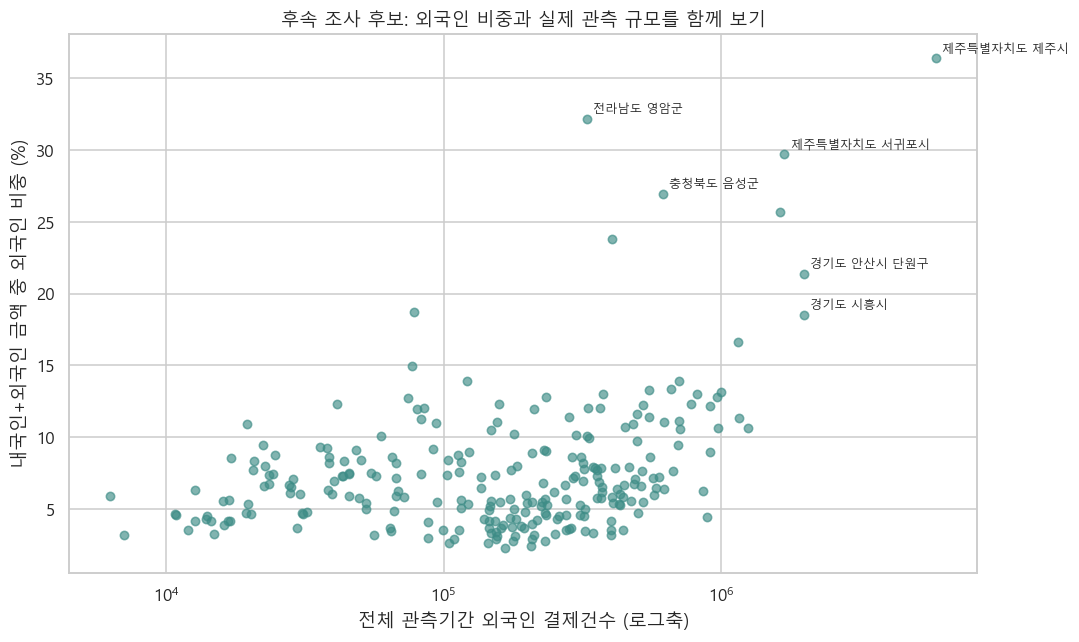

In [11]:
def foreign_candidates(data):
    s = data[data['GROUP'].isin(['내국인', '외국인'])].copy()
    by_month = s.groupby(KEY + ['STRD_YYMM', 'GROUP'], observed=True)[['AMT', 'CNT']].sum().unstack('GROUP')
    by_month.columns = [f'{m}_{g}' for m, g in by_month.columns]
    for metric in ['AMT', 'CNT']:
        for group in ['내국인', '외국인']:
            col = metric + '_' + group
            if col not in by_month:
                by_month[col] = np.nan
    by_month = by_month.reset_index()
    by_month['쌍관측'] = by_month[['AMT_내국인', 'AMT_외국인']].notna().all(axis=1)
    paired = by_month[by_month['쌍관측']].copy()
    if paired.empty:
        return pd.DataFrame(), by_month
    paired['외국인금액비중_pct'] = paired['AMT_외국인'] / (paired['AMT_내국인'] + paired['AMT_외국인']) * 100
    rg = paired.groupby(KEY, observed=True).agg(
        쌍관측월수=('STRD_YYMM', 'nunique'), 외국인금액=('AMT_외국인', 'sum'),
        내국인금액=('AMT_내국인', 'sum'), 외국인건수=('CNT_외국인', 'sum'),
        내국인건수=('CNT_내국인', 'sum'), 월비중중앙값_pct=('외국인금액비중_pct', 'median'),
        월비중표준편차_pp=('외국인금액비중_pct', 'std')).reset_index()
    rg['외국인금액비중_pct'] = rg['외국인금액'] / (rg['외국인금액'] + rg['내국인금액']) * 100
    rg['외국인건수비중_pct'] = rg['외국인건수'] / (rg['외국인건수'] + rg['내국인건수']) * 100
    rg['전체월_쌍관측'] = rg['쌍관측월수'].eq(len(months))
    rg['외국인건수기준충족'] = rg['외국인건수'] >= MIN_REGION_CNT
    return rg, by_month

candidates, foreign_monthly = foreign_candidates(df)
table('07_foreign_monthly_observation', foreign_monthly, n=5)
if candidates.empty:
    note('외국인 후보 지역: 양쪽 집단이 함께 관측된 지역·월이 없어 건너뜁니다.')
else:
    table('07_foreign_region_candidates', candidates.sort_values('외국인금액비중_pct', ascending=False))
    qualified_candidates = candidates[candidates['전체월_쌍관측'] & candidates['외국인건수기준충족']]
    table('07_foreign_candidates_by_volume', qualified_candidates.sort_values('외국인건수', ascending=False))
    plt.figure(figsize=(10, 6))
    plt.scatter(qualified_candidates['외국인건수'], qualified_candidates['외국인금액비중_pct'],
                alpha=.65, s=30, color='#3d8c86')
    if len(qualified_candidates):
        plt.xscale('log')
        labels = pd.concat([qualified_candidates.nlargest(4, '외국인건수'),
                            qualified_candidates.nlargest(4, '외국인금액비중_pct')]).drop_duplicates(KEY)
        for _, r in labels.iterrows():
            plt.annotate(r['SIDO_NM'] + ' ' + r['CCG_NM'], (r['외국인건수'], r['외국인금액비중_pct']),
                         xytext=(4, 4), textcoords='offset points', fontsize=8)
    plt.xlabel('전체 관측기간 외국인 결제건수 (로그축)')
    plt.ylabel('내국인+외국인 금액 중 외국인 비중 (%)')
    plt.title('후속 조사 후보: 외국인 비중과 실제 관측 규모를 함께 보기')
    finish_figure('07_foreign_scale_and_share')


## 9. 설정을 바꾸어도 차이가 남는가?

외국인 vs 내국인의 **슈퍼마켓**, 60대 이상 vs 20~50대의 **편의점**을 미리 정한 점검 대상으로 둡니다.
각 비교의 최소 결제건수를 바꾸어 보정 차이와 포함률을 함께 출력합니다.
추가로 '필요 업종이 모두 관측' 조건을 풀었을 때를 비교합니다. 조건을 푼 경우 **관측되지 않은 범주를 0으로 간주하는 가정**이 들어갑니다.
이 가정으로 결과가 크게 바뀌면 결론을 보류하고 미관측 행의 정의를 확인하세요.

관측량 기준은 임의의 점검 설정이며 통계적 유의성을 보장하지 않습니다.
여러 지역을 훑어 우연히 큰 차이를 찾을 수 있으므로, 상위 지역은 탐색 후보로 다루고 외부 근거로 검증하세요.


In [12]:
sensitivity_rows = []
tasks = [
    ('외국인_슈퍼마켓', foreign_age_source, 'GROUP', '내국인', '외국인',
        KEY + ['STRD_YYMM', 'AGE_CD'], BUCKETS, '슈퍼마켓'),
    ('고령층_편의점', age_source, 'AGE_GROUP', '20~50대', '60대 이상',
        KEY + ['STRD_YYMM', 'GENDER_CD'], RETAIL3, '편의점')]
for title, source, gc, g0, g1, strata, cats, target in tasks:
    configs = [(c, True) for c in sorted(set(SENSITIVITY_COUNTS + [MIN_STRATUM_CNT]))]
    configs.append((MIN_STRATUM_CNT, False))
    for minimum, complete in configs:
        r = standardized_mix(source, gc, g0, g1, strata, cats, minimum, complete)
        row = {'질문': title, '조합별_최소건수': minimum,
               '관측범주조건': '모든 범주 관측' if complete else '미관측 범주 0 가정', '공통조합수': r['n_strata']}
        if r['comparison'].empty:
            row.update({'금액비중_보정차이_pp': np.nan, '건수비중_보정차이_pp': np.nan,
                        '최저_집단별건수포함률_pct': 0.0})
        else:
            q = r['comparison'][r['comparison']['업종묶음'].eq(target)].set_index('지표')
            row['금액비중_보정차이_pp'] = q.loc['AMT', '구성보정차이_pp']
            row['건수비중_보정차이_pp'] = q.loc['CNT', '구성보정차이_pp']
            row['최저_집단별건수포함률_pct'] = r['coverage']['건수포함률_pct'].min()
        sensitivity_rows.append(row)
sensitivity = pd.DataFrame(sensitivity_rows)
table('08_sensitivity', sensitivity, n=None)
for title, sub in sensitivity.groupby('질문', observed=True):
    values = sub['금액비중_보정차이_pp'].dropna()
    if len(values):
        print(f'{title}: 설정별 금액비중 차이 범위 {values.min():.2f} ~ {values.max():.2f}%p')
        if values.min() < -1e-9 and values.max() > 1e-9:
            note(f'{title}: 설정에 따라 차이의 부호가 바뀝니다. 특정 설정의 결과만 선택하지 마세요.')


[08_sensitivity] 전체 8행; 파일에는 모든 행 저장


,질문,조합별_최소건수,관측범주조건,공통조합수,금액비중_보정차이_pp,건수비중_보정차이_pp,최저_집단별건수포함률_pct
0,외국인_슈퍼마켓,100,모든 범주 관측,5732,7.059,6.559,96.364
1,외국인_슈퍼마켓,500,모든 범주 관측,5697,7.061,6.562,96.345
2,외국인_슈퍼마켓,2000,모든 범주 관측,5258,7.104,6.612,94.995
3,외국인_슈퍼마켓,500,미관측 범주 0 가정,7159,7.202,6.633,99.495
4,고령층_편의점,100,모든 범주 관측,2372,-21.409,-26.068,97.321
5,고령층_편의점,500,모든 범주 관측,2372,-21.409,-26.068,97.321
6,고령층_편의점,2000,모든 범주 관측,2328,-21.410,-26.070,97.252
7,고령층_편의점,500,미관측 범주 0 가정,3047,-21.386,-25.971,99.993


고령층_편의점: 설정별 금액비중 차이 범위 -21.41 ~ -21.39%p
외국인_슈퍼마켓: 설정별 금액비중 차이 범위 7.06 ~ 7.20%p


## 10. 공모전 주제로 연결하기: 발견·미확인·검증을 구분

| 분석에서 확인할 내용 | 여기까지 말할 수 있음 | 외부 검증이 필요한 주장 |
|---|---|---|
| 외국인 비중이 높은 지역 + 큰 관측 규모 | 외국인 소비를 조사할 후보 지역 | 실제 거주 외국인이 많다 / 은행 이용이 어렵다 |
| 같은 지역·월·연령에서도 슈퍼마켓 비중 차이가 남음 | 관측된 업종 구성의 차이 | 소득이 낮다 / 특정 생활방식·선호 때문이다 |
| 고령층 편의점 비중 차이가 대부분 음수 | 해당 정의·표본에서 원래 가설을 지지하지 않음 | 식품 접근성이 충분하다 / 건강 위험이 없다 |
| 금액 비중과 건수 비중의 차이 | 관측 결제의 금액 구조가 업종별로 다름 | 개인이 소액결제를 자주 한다 / 혜택을 못 받는다 |
| 소비층을 고려한 지역 업종 비율이 높음 | 같은 구성의 비교 기준보다 해당 업종이 많이 관측됨 | 창업 수요가 남아 있다 / 점포 수익성이 높다 |
| 금액과 건수가 다른 방향으로 변화 | 두 기간의 관측 변화가 한 지표로 요약되지 않음 | 물가 때문 / 장기 쇠퇴 / 연체 가능성 |

실행 후 우선 볼 파일:

1. `03_foreign_region_month_age_comparison.csv`와 같은 접두사의 `coverage.csv`
2. `04_age_cvs_signed_regions.csv`
3. `05_supermarket_contextual_lift.csv`
4. `06_amount_up_count_down.csv`
5. `07_foreign_region_candidates.csv`
6. `08_sensitivity.csv`

공통표본이 부족한 분석은 자동으로 건너뛰므로 해당 결과 파일이 없을 수 있습니다.
카드 약관·외국인 인구·은행 운영시간 등 외부 자료는 자동 수집하거나 임의 생성하지 않습니다.


In [13]:
# 계산 검증: 지역 기대건수는 같은 지역의 관측 총건수와 일치해야 합니다.
if not region_lift.empty:
    check_lift = region_lift.groupby(KEY, observed=True)[['관측건수', '기대건수']].sum()
    assert np.allclose(check_lift['관측건수'], check_lift['기대건수'], rtol=1e-9, atol=1e-6)
for obj in [foreign_region, foreign_age, old_mix]:
    if not obj['comparison'].empty:
        check = obj['comparison'].groupby('지표')[['기준집단_보정비중_pct', '비교집단_보정비중_pct']].sum()
        assert np.allclose(check.to_numpy(), 100, atol=1e-8)

def file_sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

manifest = {
    'source_file': CSV_PATH.name, 'source_sha256': file_sha256(CSV_PATH),
    'created_at': datetime.now().isoformat(), 'valid_rows': len(df), 'raw_rows': len(raw),
    'months': months, 'region_definition': REGION_DEFINITION, 'foreign_definition': FOREIGN_DEFINITION,
    'config': {'min_stratum_cnt': MIN_STRATUM_CNT, 'min_region_cnt': MIN_REGION_CNT,
        'min_period_cnt': MIN_PERIOD_CNT, 'age_codes_for_comparison': CONFIRMED_AGE_CODES,
        'period_a': PERIOD_A, 'period_b': PERIOD_B, 'sensitivity_counts': SENSITIVITY_COUNTS},
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__,
                 'numpy': np.__version__, 'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__},
    'tables': SAVED_TABLES, 'notes': NOTES}
(RUN_DIR / 'run_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
summary = ['# 실행 결과 안내', '', f'- 분석 행: {len(df):,}', f'- 관측 월: {", ".join(months)}',
    f'- 원본: {CSV_PATH.name}', f'- 지역 정의: {REGION_DEFINITION}', f'- 외국인 정의: {FOREIGN_DEFINITION}',
    '', '## 표 목록', '']
summary += [f'- `{name}.csv`: {info["rows"]:,}행' for name, info in SAVED_TABLES.items()]
summary += ['', '## 실행 중 확인 사항', ''] + [f'- {n}' for n in NOTES]
summary += ['', '## 해석의 범위', '',
    '차이는 BC 관측 집계자료의 차이입니다. 금융소외, 소득, 가격, 개인별 행동, 인과관계를 직접 확인한 결과가 아닙니다.',
    '금액·건수 포함률과 민감도 표를 함께 검토하고 원래 가설과 반대되는 결과도 보고하세요.',
    '원본 데이터 및 파생 집계의 공유·제출 범위는 공모전 이용조건을 따르세요.']
(RUN_DIR / 'READ_RESULTS.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print(f'완료: {RUN_DIR.resolve()}')
print(f'CSV {len(SAVED_TABLES)}개, 그림 {len(list(FIG_DIR.glob("*.png")))}개')
print('표의 숫자는 CSV에 원래 정밀도로 저장했습니다. 표시된 소수점과 다를 수 있습니다.')


완료: C:\3-2\bigdata_analyzing\eda_new_results\20260909_165544_195114
CSV 24개, 그림 9개
표의 숫자는 CSV에 원래 정밀도로 저장했습니다. 표시된 소수점과 다를 수 있습니다.
